# Milestone P2 – Where does a caption's humour come from?
### New Yorker Caption Contest · initial analyses and data pipeline

Every week *The New Yorker* publishes a cartoon without a caption. Readers submit thousands of captions, and other readers rate them as *unfunny* (1), *somewhat funny* (2) or *funny* (3). We have **384 contests, 2.29M rated caption entries and about 290M ratings**.

**The story we want to tell.** A caption is only funny together with a picture. Our project asks where the funniness of a winning caption actually comes from:

| | Research question | Short name |
|---|---|---|
| **RQ1** | When the *same words* appear under different cartoons, how much of their score travels with the text, and how much depends on the picture? | *Same words, different joke* |
| **RQ2** | Do winners have *original* ideas, or do they express a *common* idea particularly well? | *A common thought, perfectly expressed* |
| **RQ3** | Can current vision-language models write captions that the audience would rate like human entries, judged by a model trained on these ratings? | *Can AI please the crowd?* |

**What this notebook does (Milestone P2 checklist)**

| Section | Milestone requirement |
|---|---|
| 1. Loading | we can handle the data in its size |
| 2–4. Content, quality, descriptive statistics | we understand formats, distributions, missing values and correlations |
| 5–6. Comparable scores and enrichment | we filter, transform and enrich the data for our needs |
| 7. Feasibility, one pilot per RQ | each research question can be answered with this data |
| 8–10. Methods, extra data, alternatives | a reasonable plan with the essential maths, and the options we dropped |

All non-trivial logic lives in [`src/`](src/) and is imported here. The notebook runs top to bottom in about 2 minutes on a laptop with 16 GB RAM.

> **Use of LLMs (course requirement).** An LLM assistant (Claude) helped draft parts of the code in `src/` and of the text in this notebook. All analyses were run, checked and interpreted by the team.

In [1]:
%load_ext autoreload
%autoreload 2

import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image
from scipy import stats

from src.data_loading import find_data_dir, load_captions, load_contests, RATING_COLUMNS
from src.quality import add_quality_flags, quality_report, FIRST_CROWDSOURCED_CONTEST
from src.scoring import add_scores, aggregate_text, icc_oneway, bootstrap_icc
from src.text import add_text_features, nearest_captions, crowd_sizes
from src.judge import training_sample, cross_validated_judge, pairwise_accuracy, fit_judge

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8985"

DATA_DIR = find_data_dir()
CACHE = Path("data")
print("dataset folder:", DATA_DIR)

dataset folder: ../newyorker_caption_contest


## 1. Loading the data – can we handle its size?

The raw data are 384 CSV files (231 MB, one per contest), 385 JPEG cartoons (212 MB) and one `contests.json` with metadata.
`load_captions` concatenates the CSVs into one table, downcasts the dtypes (`int32`, `float32`, `int16`), and caches the result as **parquet**. The first run takes a few seconds; later runs read the cache in about 1 s.

In [2]:
t0 = time.time()
captions = load_captions(DATA_DIR, cache=CACHE / "captions.parquet")
contests = load_contests(DATA_DIR)
print(f"loaded in {time.time() - t0:.1f} s")
print(f"caption entries: {len(captions):,}  |  contests: {captions.contest_id.nunique()}  |  "
      f"ratings: {captions.votes.sum():,}")
print(f"memory: {captions.memory_usage(deep=True).sum() / 1e6:.0f} MB (most of it is the caption strings)")
captions.head()

loaded in 0.6 s
caption entries: 2,292,678  |  contests: 384  |  ratings: 291,112,695
memory: 338 MB (most of it is the caption strings)


,contest_id,caption,mean,precision,votes,not_funny,somewhat_funny,funny
0,510,I'm a congressman--obstruction is my job.,1.913043,0.094022,69,24,27,18
1,510,"I'm what they mean when they say, 'The middle class is getting stepped on.'",1.842105,0.191381,19,8,6,5
2,510,Does this suit make me look flat?,1.711111,0.112915,45,21,16,8
3,510,"When the right woman comes along, I'll know it.",1.625000,0.116657,32,15,14,3
4,510,"I used to lie in the gutter, but then I quit drinking.",1.617647,0.133610,34,19,9,6


**Takeaway.** The data fits comfortably in memory: about 360 MB, of which most is caption text. Every operation in this notebook is vectorised or grouped by contest, so nothing needs chunking.
The only expensive step we plan is computing **sentence and image embeddings** (Section 8). We will run it once on the *unique* normalised captions and cache the result. Section 6 counts how many unique captions there are.

## 2. What is in the data?

### 2.1 Formats

In [3]:
schema = pd.DataFrame({
    "dtype": captions.dtypes.astype(str),
    "missing": captions.isna().sum(),
    "description": {
        "contest_id": "id of the weekly contest (ordering only, no date in the data)",
        "caption": "text of the submitted caption",
        "mean": "average rating, 1 = unfunny … 3 = funny",
        "precision": "reported standard error of `mean` (checked in Section 3)",
        "votes": "number of ratings received",
        "not_funny": "number of 1-ratings", "somewhat_funny": "number of 2-ratings",
        "funny": "number of 3-ratings"}})
schema

,dtype,missing,description
contest_id,int16,0,"id of the weekly contest (ordering only, no date in the data)"
caption,object,52,text of the submitted caption
mean,float32,0,"average rating, 1 = unfunny … 3 = funny"
precision,float32,0,reported standard error of `mean` (checked in Section 3)
votes,int32,0,number of ratings received
not_funny,int32,0,number of 1-ratings
somewhat_funny,int32,0,number of 2-ratings
funny,int32,0,number of 3-ratings


The original files also contain a `rank` column, but only 148 of the 384 files have it. We drop it and recompute ranks the same way for every contest.
Each contest in `contests.json` may have **metadata** from Hessel et al. (2023): a location, human descriptions, an "uncanny" description (what is odd in the picture), Wikipedia entities and questions. We flatten it into one row per contest:

In [4]:
print(f"contests with metadata: {contests.has_metadata.sum()} / {len(contests)}")
contests[contests.has_metadata].head(3)

contests with metadata: 240 / 384


,has_metadata,location,description,uncanny,entities,n_descriptions
contest_id,,,,,,
510,True,street,A man is relaxing on a city street. Others are going about their business and stepping...,A man is just laying in the middle of the sidewalk.,"[Bystander_effect, Crowd]",1
511,True,front hard,A man in a winter coat and cap is looking at a small bearded man holding a snow shovel...,"It's unusual to see someone holding a snow shovel in the way the man is, as well as to...","[Snowball_fight, Winter, Snow_removal, Snow_shovel]",3
512,True,yoga place,A man and woman are standing facing one another (mirrored) inside of a yoga studio. Th...,Nothing is really out of place in this image.,"[Rug, Yoga_mat, Carpet]",3


### 2.2 Coverage: which contests have what?

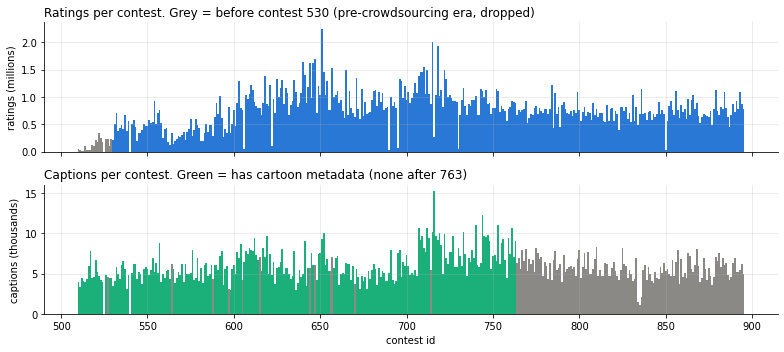

contest ids with no CSV: [525, 540]


In [5]:
per_contest = captions.groupby("contest_id").agg(n_captions=("caption", "size"), n_votes=("votes", "sum"))
per_contest = per_contest.join(contests["has_metadata"])
ids = per_contest.index

fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].bar(ids, per_contest.n_votes / 1e6, color=np.where(ids < FIRST_CROWDSOURCED_CONTEST, GREY, BLUE), width=1)
axes[0].set_ylabel("ratings (millions)")
axes[0].set_title("Ratings per contest. Grey = before contest 530 (pre-crowdsourcing era, dropped)", loc="left")
axes[1].bar(ids, per_contest.n_captions / 1e3, color=np.where(per_contest.has_metadata, GREEN, GREY), width=1)
axes[1].set_ylabel("captions (thousands)")
axes[1].set_title("Captions per contest. Green = has cartoon metadata (none after 763)", loc="left")
axes[1].set_xlabel("contest id")
plt.tight_layout(); plt.show()

missing_ids = sorted(set(range(ids.min(), ids.max() + 1)) - set(ids))
print("contest ids with no CSV:", missing_ids)

**Observations**
- Contests **510–529** received only 17k–350k ratings each, compared with 0.5–1M afterwards. The paper says crowdsourced rating started with **contest 530**, and its dataset covers exactly 530–895: 365 contests, which we also have. We therefore keep **contests ≥ 530**.
- Contests 525 and 540 have no CSV (540 has an image only).
- Metadata covers **240 contests**, almost all before contest 764. Any analysis that uses it covers an earlier period. This matters for RQ1 and RQ3, which may need image descriptions, so in Section 9 we plan to compute image embeddings for *all* cartoons ourselves.

## 3. Data quality and cleaning

We check every row for internal consistency. `add_quality_flags` marks a row as **valid** if
1. the three rating counts add up to `votes`;
2. the reported `mean` equals $(n_1 + 2n_2 + 3n_3)/N$ and lies in $[1, 3]$;
3. `precision` is finite (it is `inf` when a caption has one vote);
4. the contest is from the crowdsourcing era (≥ 530);
5. the caption text is not missing.

In [6]:
captions = add_quality_flags(captions)
quality_report(captions)

,rows,share
missing caption text,52,0.00%
counts do not sum to votes,7175,0.31%
"mean differs from counts / outside [1,3]",28142,1.23%
infinite precision (1 vote),79,0.00%
pre-crowdsourcing contest (< 530),89948,3.92%
exact duplicate record,324,0.01%
any problem (not valid),118301,5.16%


In [7]:
# Do the problems concentrate in a few contests?
era = captions[captions.crowdsourced]
bad_share = (~era.counts_ok | ~era.mean_ok).groupby(era.contest_id).mean()
print(f"contests with any inconsistent row: {(bad_share > 0).sum()} / {len(bad_share)}")
print(f"contests with > 5% inconsistent rows: {(bad_share > 0.05).sum()}")
display(bad_share.nlargest(5).rename("share of inconsistent rows").to_frame().T.round(3))

# What do the inconsistencies look like?
diff = (era.not_funny + era.somewhat_funny + era.funny - era.votes)[~era.counts_ok]
print("rating categories minus votes, for inconsistent rows:", diff.value_counts().head(4).to_dict())

contests with any inconsistent row: 154 / 365
contests with > 5% inconsistent rows: 35


contest_id,706,835,811,703,718
share of inconsistent rows,0.146,0.13,0.117,0.11,0.103


rating categories minus votes, for inconsistent rows: {-1: 5040, -2: 985, -3: 442, -4: 204}


In [8]:
# Is `precision` really a standard error? Recompute it from the counts on valid rows.
v = captions[captions.valid]
var = (v.not_funny * (1 - v["mean"])**2 + v.somewhat_funny * (2 - v["mean"])**2
       + v.funny * (3 - v["mean"])**2) / (v.votes - 1)
se = np.sqrt(var / v.votes)
print(f"precision == sample standard error (tolerance 1e-4): {(np.abs(se - v.precision) < 1e-4).mean():.1%}")

precision == sample standard error (tolerance 1e-4): 94.4%


**Cleaning decisions**

| Issue | Size | Decision | Why |
|---|---|---|---|
| Pre-crowdsourcing contests (510–529) | 3.9% of rows | **drop** | different rating system, very few votes |
| Counts ≠ votes, or mean ≠ counts | ~1.5% of rows, in 154 of 365 contests (> 5% of rows in 35 contests) | **drop**, plus sensitivity check in P3 | cause unknown; usually 1–2 ratings are missing from the categories. We do not repair data we do not understand |
| `inf` precision (1 vote) | 79 rows | **drop** | no uncertainty estimate |
| Missing caption text | 52 rows | **drop** | nothing to analyse |
| Exact duplicate records | 324 rows | keep (negligible) | could be genuine double submissions |
| Same text submitted several times in a contest (different ratings) | ~22k rows | **keep** as separate entries | a free *test–retest* measurement (used in RQ1). For text-level analyses we average them |

`precision` matches the sample standard error $\sqrt{s^2/N}$ for valid rows, so we can use it as the uncertainty of `mean`.

In [9]:
df = captions[captions.valid].copy()
print(f"kept {len(df):,} of {len(captions):,} rows ({len(df) / len(captions):.1%}) "
      f"in {df.contest_id.nunique()} contests")

kept 2,174,377 of 2,292,678 rows (94.8%) in 365 contests


## 4. Descriptive statistics

### 4.1 Caption-level distributions

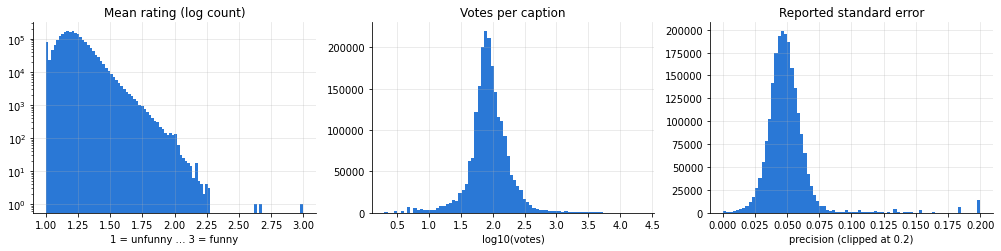

,count,mean,std,min,1%,25%,50%,75%,99%,max
mean,2174377.0,1.212,0.118,1.0,1.000,1.135,1.200,1.274,1.582,2.999
votes,2174377.0,124.804,284.162,2.0,7.000,63.000,85.000,125.000,766.000,21705.000
precision,2174377.0,0.051,0.026,0.0,0.019,0.041,0.048,0.056,0.164,1.000


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(df["mean"], bins=100, color=BLUE)
axes[0].set_yscale("log"); axes[0].set_title("Mean rating (log count)"); axes[0].set_xlabel("1 = unfunny … 3 = funny")
axes[1].hist(np.log10(df.votes), bins=80, color=BLUE)
axes[1].set_title("Votes per caption"); axes[1].set_xlabel("log10(votes)")
axes[2].hist(df.precision.clip(upper=0.2), bins=80, color=BLUE)
axes[2].set_title("Reported standard error"); axes[2].set_xlabel("precision (clipped at 0.2)")
plt.tight_layout(); plt.show()

df[["mean", "votes", "precision"]].describe(percentiles=[.01, .25, .5, .75, .99]).T.round(3)

In [11]:
shares = df[RATING_COLUMNS].sum() / df.votes.sum()
print("share of all ratings:", shares.round(3).to_dict())
print(f"captions with mean > 1.5: {(df['mean'] > 1.5).mean():.2%}   |   mean > 2: {(df['mean'] > 2).mean():.3%}")

share of all ratings: {'not_funny': 0.739, 'somewhat_funny': 0.189, 'funny': 0.072}
captions with mean > 1.5: 2.18%   |   mean > 2: 0.014%


- Ratings are dominated by *unfunny*: about 74% of all ratings, against 7% *funny*. The typical caption scores about 1.2. Only about 2% exceed 1.5, and about 300 exceed 2.
- Votes are **right-skewed**: the median caption gets about 85 votes, while the top captions get thousands. Section 4.3 shows that this comes from the bandit.
- Standard errors are mostly 0.02–0.08, which is large compared with the gaps between neighbouring captions. Ranks in the middle of the distribution are therefore very noisy.

### 4.2 Contest-level statistics

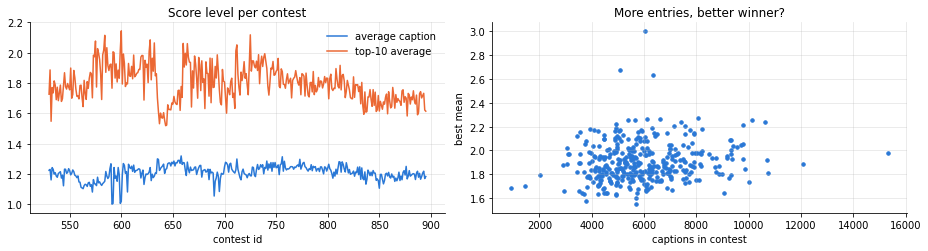

Spearman(n_captions, best_mean) = 0.16 (p = 0.0016)


,n_captions,n_votes,avg_mean,best_mean,top10_mean
count,365.00,365.00,365.00,365.00,365.00
mean,5957.20,743480.88,1.21,1.90,1.80
std,1738.98,286313.33,0.05,0.17,0.12
min,926.00,31131.00,1.00,1.55,1.52
25%,4771.00,593171.00,1.19,1.79,1.71
50%,5694.00,740813.00,1.22,1.88,1.79
75%,6944.00,892788.00,1.24,1.99,1.88
max,15327.00,2249813.00,1.32,3.00,2.14


In [12]:
contest_stats = df.groupby("contest_id").agg(
    n_captions=("caption", "size"), n_votes=("votes", "sum"),
    avg_mean=("mean", "mean"), best_mean=("mean", "max"))
contest_stats["top10_mean"] = df[df["mean"].groupby(df.contest_id).rank(ascending=False) <= 10] \
    .groupby("contest_id")["mean"].mean()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
axes[0].plot(contest_stats.index, contest_stats.avg_mean, color=BLUE, label="average caption")
axes[0].plot(contest_stats.index, contest_stats.top10_mean, color=ORANGE, label="top-10 average")
axes[0].set_title("Score level per contest"); axes[0].set_xlabel("contest id"); axes[0].legend(frameon=False)
axes[1].scatter(contest_stats.n_captions, contest_stats.best_mean, s=12, color=BLUE)
axes[1].set_xlabel("captions in contest"); axes[1].set_ylabel("best mean")
axes[1].set_title("More entries, better winner?")
plt.tight_layout(); plt.show()

r, p = stats.spearmanr(contest_stats.n_captions, contest_stats.best_mean)
print(f"Spearman(n_captions, best_mean) = {r:.2f} (p = {p:.2g})")
contest_stats.describe().round(2)

Contests differ in level: some cartoons are simply easier to caption, and the audience may have changed over time. **Raw means should therefore not be compared across contests.** Section 5 standardises scores within each contest.

### 4.3 The bandit: votes are not given at random
The paper says a UCB-style bandit shows promising captions more often. We check this in the data:

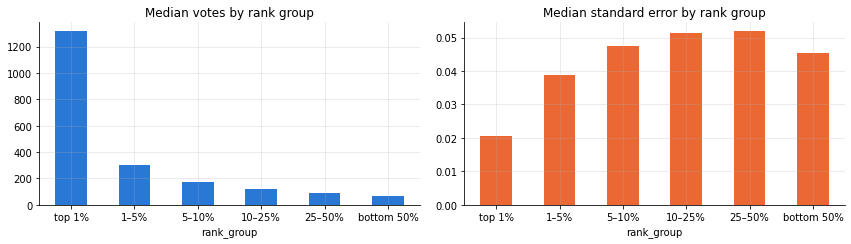

rank_group,top 1%,1–5%,5–10%,10–25%,25–50%,bottom 50%
median_votes,1317.00,299.000,176.000,124.000,91.000,69.000
median_se,0.02,0.039,0.047,0.051,0.052,0.045


In [13]:
bins = [0, 0.01, 0.05, 0.10, 0.25, 0.5, 1.0]
labels = ["top 1%", "1–5%", "5–10%", "10–25%", "25–50%", "bottom 50%"]
df["rank_group"] = pd.cut(df.groupby("contest_id")["mean"].rank(ascending=False, pct=True), bins, labels=labels)
by_group = df.groupby("rank_group", observed=True).agg(median_votes=("votes", "median"),
                                                        median_se=("precision", "median"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
by_group.median_votes.plot.bar(ax=axes[0], color=BLUE, rot=0, title="Median votes by rank group")
by_group.median_se.plot.bar(ax=axes[1], color=ORANGE, rot=0, title="Median standard error by rank group")
plt.tight_layout(); plt.show()
by_group.round(3).T

The top 1% of captions receive about **20× more votes** than the bottom half, so they have much smaller standard errors. This has three consequences for our methods:
1. Missing votes are **not missing at random**: low-ranked captions are measured less precisely *because* they looked bad early on.
2. Weighting by votes would mostly weight the captions the bandit already favoured. We use equal weights and model uncertainty explicitly (Section 5).
3. Comparisons near the top are informative. Comparisons in the long tail are noisy.

### 4.4 Correlations between caption-level variables

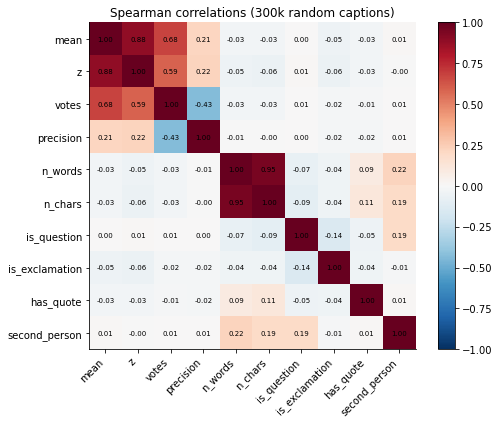

In [14]:
df = add_text_features(df)
df = add_scores(df)

corr_cols = ["mean", "z", "votes", "precision", "n_words", "n_chars", "is_question",
             "is_exclamation", "has_quote", "second_person"]
corr = df[corr_cols].sample(300_000, random_state=0).astype(float).corr(method="spearman")

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False); plt.colorbar(im, fraction=0.046); ax.set_title("Spearman correlations (300k random captions)")
plt.tight_layout(); plt.show()

- `mean` and `votes` are strongly positively correlated ($\rho \approx 0.68$), which again shows the bandit. `precision` falls with `votes`, as expected for a standard error, but *rises* with `mean`: a caption that only gets 1s has zero spread, while a funnier caption gets mixed ratings.
- **Surface text features hardly correlate with the score** ($|\rho| \le 0.06$). Length, question marks or addressing "you" do not explain much, so what makes a caption funny must come from its *content* and its *fit with the cartoon*. This is what our research questions are about.

## 5. Making scores comparable

Raw means have two problems. (i) Contests have different levels (Section 4.2). (ii) A caption with 15 votes and a mean of 1.6 is much less certain than one with 2,000 votes and the same mean. `add_scores` adds three columns:

- **`rank`, `rank_pct`**: the observed position within the contest (1 = best). This is descriptive only.
- **`z`**: the mean standardised within the contest, $z_i = (x_i - \bar x_c)/s_c$. We use it to compare captions *across* contests.
- **`eb_mean`**: an **empirical-Bayes (shrinkage) estimate**. Within each contest $c$ we assume

$$x_i \mid \mu_i \sim \mathcal N(\mu_i, s_i^2), \qquad \mu_i \sim \mathcal N(m_c, \tau_c^2)$$

where $x_i$ is the observed mean, $s_i$ the reported `precision` and $\mu_i$ the caption's *true* funniness. By the method of moments, $\hat m_c = \overline{x}$ and $\hat\tau_c^2 = \max(\mathrm{Var}(x) - \overline{s^2}, \varepsilon)$. The posterior mean is

$$\hat\mu_i = w_i\,x_i + (1-w_i)\,\hat m_c, \qquad w_i = \frac{\hat\tau_c^2}{\hat\tau_c^2 + s_i^2}.$$

Captions with few votes (large $s_i$) are pulled toward the contest average. Well-measured captions barely move.

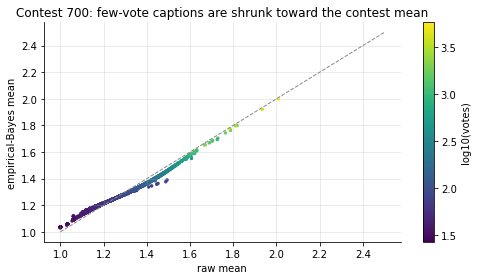

median shrinkage weight w: 0.79
raw top-10 captions still in the EB top-10: 94.2%
contests where the raw winner is also the EB winner: 91.8%


In [15]:
example = df[df.contest_id == 700]
fig, ax = plt.subplots(figsize=(7, 4))
sc = ax.scatter(example["mean"], example["eb_mean"], c=np.log10(example.votes), s=6, cmap="viridis")
ax.plot([1, 2.5], [1, 2.5], color=GREY, lw=1, ls="--")
ax.set_xlabel("raw mean"); ax.set_ylabel("empirical-Bayes mean")
ax.set_title("Contest 700: few-vote captions are shrunk toward the contest mean")
plt.colorbar(sc, label="log10(votes)"); plt.tight_layout(); plt.show()

df["eb_rank"] = df.groupby("contest_id")["eb_mean"].rank(ascending=False, method="first")
top10 = df[df["rank"] <= 10]
print(f"median shrinkage weight w: {df.eb_weight.median():.2f}")
print(f"raw top-10 captions still in the EB top-10: {(top10.eb_rank <= 10).mean():.1%}")
print(f"contests where the raw winner is also the EB winner: {(df[df['rank'] == 1].eb_rank == 1).mean():.1%}")

Shrinkage hardly changes the top of the ranking: the bandit already measures the top captions precisely. It does change the **long tail**, where most of our analyses (idea clusters, repeated captions) take place. We will use `z` for comparisons across contests and `eb_mean` and the standard errors whenever single captions are compared.

## 6. Enrichment and transformation

### 6.1 Text normalisation and features
`add_text_features` normalises captions: lower case, unified quotes, no punctuation. "Who farted?" and "who farted!" thus count as the same text. It also adds a few surface features. Their association with the within-contest score `z`:

,share of captions,mean z if True,mean z if False
feature,,,
is_question,0.148,0.009,-0.002
is_exclamation,0.107,-0.158,0.019
has_quote,0.065,-0.097,0.007
second_person,0.337,-0.001,0.000


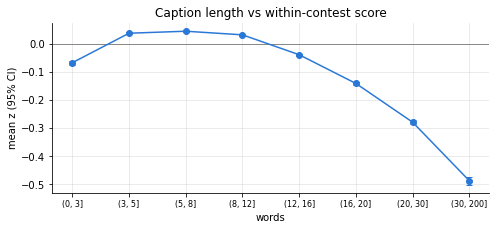

unique normalised captions: 2,112,969 (97% of entries) -> 1.6 GB as 384-dim float16 embeddings


In [16]:
features = ["is_question", "is_exclamation", "has_quote", "second_person"]
rows = []
for f in features:
    g = df.groupby(f)["z"]
    rows.append({"feature": f, "share of captions": df[f].mean(), "mean z if True": g.mean()[True],
                 "mean z if False": g.mean()[False]})
display(pd.DataFrame(rows).set_index("feature").round(3))

length = df.groupby(pd.cut(df.n_words, [0, 3, 5, 8, 12, 16, 20, 30, 200]), observed=True)["z"].agg(["size", "mean", "sem"])
fig, ax = plt.subplots(figsize=(7, 3.3))
ax.errorbar(range(len(length)), length["mean"], yerr=1.96 * length["sem"], color=BLUE, marker="o", capsize=3)
ax.set_xticks(range(len(length))); ax.set_xticklabels([str(i) for i in length.index], rotation=0, fontsize=8)
ax.axhline(0, color=GREY, lw=1); ax.set_xlabel("words"); ax.set_ylabel("mean z (95% CI)")
ax.set_title("Caption length vs within-contest score"); plt.tight_layout(); plt.show()

n_unique = df.caption_norm.nunique()
print(f"unique normalised captions: {n_unique:,} ({n_unique / len(df):.0%} of entries) -> "
      f"{n_unique * 384 * 2 / 1e9:.1f} GB as 384-dim float16 embeddings")

Captions between 4 and 12 words do best. Very short captions are slightly worse, and long ones are clearly worse: −0.3 to −0.5 standard deviations above 20 words, though these are only about 4% of captions. Exclamation marks and quotes also go with lower scores. Captions of normal length all score about the same, so length mainly filters out bad captions and does not explain the good ones. The number of unique captions shows that **embedding all of them is feasible** (about 1.6 GB). A small sentence encoder takes a few hours on CPU or minutes on a GPU (Colab / EPFL cluster).

### 6.2 Cartoon metadata

In [17]:
meta = contests[contests.has_metadata].join(contest_stats, how="inner")
meta["z_best"] = (meta.best_mean - meta.best_mean.mean()) / meta.best_mean.std()
top_locations = meta.location.value_counts().head(8)

loc = meta[meta.location.isin(top_locations.index)].groupby("location").agg(
    contests=("best_mean", "size"), best_mean=("best_mean", "mean"), avg_mean=("avg_mean", "mean"))
display(loc.sort_values("contests", ascending=False).round(3))

entities = meta.entities.explode().value_counts()
print(f"{meta.location.nunique()} distinct locations, {len(entities)} distinct Wikipedia entities "
      f"(median {meta.entities.str.len().median():.0f} per cartoon)")
print("most common entities:", entities.head(10).index.tolist())

,contests,best_mean,avg_mean
location,,,
living room,15,1.972,1.218
restaurant,9,1.893,1.245
cave,8,1.979,1.198
kitchen,6,1.974,1.205
field,5,2.008,1.235
ocean,5,2.088,1.194
sidewalk,5,1.938,1.219
desert,4,1.943,1.217


139 distinct locations, 470 distinct Wikipedia entities (median 3 per cartoon)
most common entities: ['Caveman', 'Waiting_staff', 'Dog', 'Hiking', 'Mouse', 'Cat', 'White-collar_worker', 'Anthropomorphism', 'Death_(personification)', 'Chef']


Cartoons fall into recurring **settings** (living rooms, restaurants, offices, caves, desert islands) and **stock characters** (Death, cavemen, kings, talking animals). With at most about 20 contests per setting, location-level comparisons are too noisy to support strong conclusions, so we will use the metadata to **describe and group** cartoons rather than as a main explanatory variable. Because the metadata stops at contest 763, the image representation for RQ1 and RQ3 will come from embeddings we compute ourselves for all cartoons (Section 9).

## 7. Feasibility: a first pilot for each research question

### RQ1 – Same words, different joke
Some captions are submitted again and again under different cartoons ("Who farted?", "It's a living!"). The text stays fixed while the picture changes, which is an observational experiment on context.

We compare two settings using the **intra-class correlation (ICC)**, i.e. the share of score variance explained by "which text it is":
- **same text, same cartoon** (repeated submissions within one contest). Only the rating noise differs, so this is a *reliability ceiling*.
- **same text, different cartoons** (captions found in ≥ 5 contests). Rating noise, picture *and* period all differ.

The ICC comes from a one-way random-effects ANOVA, $z_{gj} = \mu + a_g + e_{gj}$:
$$\mathrm{ICC} = \frac{\sigma_a^2}{\sigma_a^2+\sigma_e^2},\quad \hat\sigma_a^2 = \frac{MSB - MSW}{n_0},\quad n_0 = \frac{N - \sum_g n_g^2/N}{G-1}.$$
Confidence intervals come from a **cluster bootstrap** that resamples whole groups. Only entries with ≥ 20 votes are used.

In [18]:
txt = df[(df.caption_norm != "") & (df.votes >= 20)]

# Same text, different cartoons: one row per (contest, text), averaged over repeated entries.
per_text = aggregate_text(txt)
n_contests = per_text.groupby("caption_norm").contest_id.transform("nunique")
across = per_text[n_contests >= 5]
recurring = set(across.caption_norm)

# Same text, same cartoon: repeated submissions inside one contest.
within = txt[txt.duplicated(["contest_id", "caption_norm"], keep=False)]
within = within.assign(group=within.contest_id.astype(str) + "|" + within.caption_norm)

results = []
for name, data, group in [("same text, same cartoon (all)", within, "group"),
                          ("same text, same cartoon (recurring captions only)",
                           within[within.caption_norm.isin(recurring)], "group"),
                          ("same text, different cartoons", across, "caption_norm")]:
    r = icc_oneway(data, group, "z")
    lo, hi = bootstrap_icc(data, group, "z")
    results.append({"setting": name, "texts": r["groups"], "observations": r["observations"],
                    "ICC": r["icc"], "95% CI": f"[{lo:.2f}, {hi:.2f}]"})
icc_table = pd.DataFrame(results).set_index("setting")
icc_table.round(3)

,texts,observations,ICC,95% CI
setting,,,,
"same text, same cartoon (all)",10314,21143,0.524,"[0.50, 0.55]"
"same text, same cartoon (recurring captions only)",788,1809,0.648,"[0.52, 0.71]"
"same text, different cartoons",1577,13532,0.225,"[0.20, 0.25]"


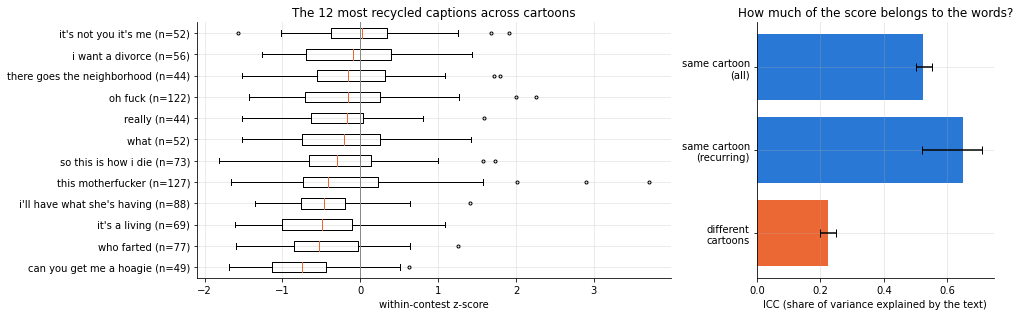

In [19]:
top_stock = across.groupby("caption_norm").z.agg(["size", "median"]).nlargest(12, "size").sort_values("median")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [2, 1]})
axes[0].boxplot([across.loc[across.caption_norm == t, "z"] for t in top_stock.index], vert=False,
                labels=[f"{t[:35]} (n={n})" for t, n in zip(top_stock.index, top_stock["size"])],
                medianprops={"color": ORANGE}, flierprops={"markersize": 3})
axes[0].axvline(0, color=GREY, lw=1)
axes[0].set_xlabel("within-contest z-score"); axes[0].set_title("The 12 most recycled captions across cartoons")

ci = icc_table["95% CI"].str.strip("[]").str.split(", ", expand=True).astype(float)
axes[1].barh(range(3), icc_table.ICC, xerr=[icc_table.ICC - ci[0], ci[1] - icc_table.ICC],
             color=[BLUE, BLUE, ORANGE], capsize=4)
axes[1].set_yticks(range(3)); axes[1].set_yticklabels(["same cartoon\n(all)", "same cartoon\n(recurring)", "different\ncartoons"])
axes[1].set_xlabel("ICC (share of variance explained by the text)"); axes[1].invert_yaxis()
axes[1].set_title("How much of the score belongs to the words?")
plt.tight_layout(); plt.show()

**What we learn (RQ1 is feasible and promising)**
- About 1,600 normalised captions appear in ≥ 5 contests with enough votes, about 13,500 (contest, text) pairs in total. That is enough for a proper model.
- Identical words *under the same cartoon* reach an ICC of about **0.5–0.65**. Identical words *under different cartoons* reach only about **0.23**. When the picture changes, well over half of the reproducible part of a caption's score disappears. This is the context effect RQ1 is about. The same caption ranges from clearly below average to clearly above average depending on the cartoon (left plot).
- **Caveats.** Recycled captions are mostly generic one-liners and score below average. The period and the audience change together with the cartoon, so the gap is an *upper bound* on the picture effect. Section 8 explains how we separate these.

### RQ2 – A common thought, perfectly expressed
For each caption we measure its **idea crowd size**: how many *other* captions in the same contest are lexically similar (TF-IDF cosine ≥ 0.4 on word 1–2-grams). This is a cheap proxy for how many people had the same idea. Example: contest 665.

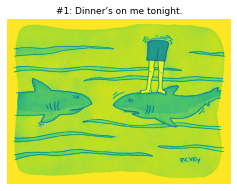

,similarity,caption,mean,votes,rank
128,0.58,Takeout is on me tonight.,1.464179,670,129
184,0.50,Suppers on me!,1.437970,532,185
193,0.48,"Hey, Frank, dinner’s on me, today.",1.434783,506,194
1211,0.37,Snacks on me!,1.306011,183,1212
2113,0.37,Dinner's on the table.,1.259259,135,2114
1926,0.32,Get washed up. Dinner's on the table.,1.268965,145,1927
81,0.29,This one’s on me.,1.503817,1048,82
1463,0.27,I picked up dinner on the way home.,1.290909,165,1464


In [20]:
c665 = df[df.contest_id == 665].sort_values("rank").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(Image.open(DATA_DIR / "images" / "665.jpg")); ax.axis("off")
ax.set_title(f"#1: {c665.caption[0]}", fontsize=9); plt.show()
nearest_captions(c665, 0, k=8)

,median,mean,share_unique
group,,,
random caption,1.0,3.16,0.39
top 10,2.0,3.96,0.26


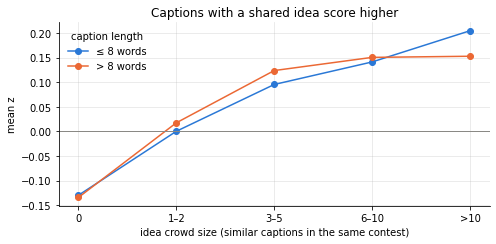

Spearman(crowd size, z) on 72,843 random captions: 0.12 (p = 2e-234)


In [21]:
crowd = crowd_sizes(df)
crowd["group"] = np.where(crowd["rank"] <= 10, "top 10", "random caption")
crowd["crowd_bin"] = pd.cut(crowd.crowd, [-1, 0, 2, 5, 10, 10_000], labels=["0", "1–2", "3–5", "6–10", ">10"])

summary = crowd.groupby("group").crowd.agg(median="median", mean="mean", share_unique=lambda s: (s == 0).mean())
display(summary.round(2))

rand = crowd[crowd.group == "random caption"].dropna(subset=["crowd"])
by_bin = rand.groupby(["crowd_bin", rand.n_words > 8], observed=True).z.mean().unstack()
by_bin.columns = ["≤ 8 words", "> 8 words"]

fig, ax = plt.subplots(figsize=(7, 3.5))
for col, color in zip(by_bin.columns, [BLUE, ORANGE]):
    ax.plot(by_bin.index.astype(str), by_bin[col], marker="o", color=color, label=col)
ax.axhline(0, color=GREY, lw=1); ax.legend(frameon=False, title="caption length")
ax.set_xlabel("idea crowd size (similar captions in the same contest)"); ax.set_ylabel("mean z")
ax.set_title("Captions with a shared idea score higher"); plt.tight_layout(); plt.show()

rho, p = stats.spearmanr(rand.crowd, rand.z)
print(f"Spearman(crowd size, z) on {len(rand):,} random captions: {rho:.2f} (p = {p:.1g})")

**What we learn (RQ2)**
- Top-10 captions are *less* often unique (about 26% have no lexical neighbour, against about 39% of random captions). Captions whose idea many people share score higher, and the pattern holds for both short and long captions. As a first signal, "great minds think alike" seems more accurate than "the winner is the one nobody else thought of".
- **The limitation is visible in the example.** TF-IDF finds "Takeout is on me tonight" but misses paraphrases with no shared words. For the project we will use **sentence embeddings** and cluster them into *joke ideas* (Section 8), then compare wordings *within* an idea.
- This pilot is the "convergence" half of RQ2. The "wording" half needs the clusters first.

### RQ3 – Can AI please the crowd? A first baseline judge
To compare AI captions with human entries we need a **judge** that predicts how this audience would rate a caption for a cartoon it has never seen. Before building anything multimodal, we test how far **text alone** goes:
- **Model:** TF-IDF (1–2-grams) and ridge regression predicting `z`, $\hat\beta = \arg\min_\beta \|z - X\beta\|^2 + \alpha\|\beta\|^2$.
- **Data:** per contest the top 50, ranks 1000–1009 and 400 random captions.
- **Evaluation:** 5-fold **GroupKFold by contest**, so every prediction is for an unseen cartoon. As metric we use the paper's *pairwise ranking accuracy*: how often a top-10 caption gets a higher predicted score than a caption ranked #1000–1009 (chance = 50%).

In [22]:
t0 = time.time()
sample = training_sample(df)
judged = cross_validated_judge(sample)
acc = pairwise_accuracy(judged)
per_contest_acc = judged.groupby("contest_id").apply(pairwise_accuracy)
half_width = 1.96 * per_contest_acc.std() / np.sqrt(len(per_contest_acc))
print(f"{len(sample):,} captions, {time.time() - t0:.0f} s")
print(f"pairwise accuracy on held-out contests: {acc:.1%} ± {half_width:.1%} (95% CI over contests)")

paper = pd.DataFrame({"pairwise accuracy (%)": [61.7, 61.0, 60.5, 66.5, round(100 * acc, 1)]},
                     index=["crowd workers (paper)", "GPT-4-Turbo-vision, image (paper)", "GPT-4o-vision, image (paper)",
                            "GPT-4-Turbo + human descriptions (paper)", "our text-only ridge baseline"])
paper

167,890 captions, 9 s
pairwise accuracy on held-out contests: 63.0% ± 1.4% (95% CI over contests)


,pairwise accuracy (%)
crowd workers (paper),61.7
"GPT-4-Turbo-vision, image (paper)",61.0
"GPT-4o-vision, image (paper)",60.5
GPT-4-Turbo + human descriptions (paper),66.5
our text-only ridge baseline,63.0


In [23]:
# Only terms used in >= 50 different contests, so we see general style rather than cartoon-specific words.
coefs = fit_judge(sample, min_contests=50)
pd.DataFrame({"pushes score down": coefs.head(15).index, "pushes score up": coefs.tail(15).index[::-1]})

,pushes score down,pushes score up
0,covid,white house
1,hey,middle
2,sauce,cancel
3,share,situation
4,world,either
5,were the,identify
6,trade,part is
7,ya,suddenly
8,halloween,it always
9,of,surprised


**What we learn (RQ3)**
- A text-only linear model already ranks top-10 captions above #1000-level captions about **63%** of the time on unseen cartoons. That is about as good as crowd workers and GPT-4 *pairwise* in the paper (60–67%). The protocols are similar but not identical: the paper uses 200 sampled pairs, we use all top-10 × #1000 pairs.
- Among general terms, the model mostly learns **register**: casual openers ("hey", "ya") and topical references ("covid", "halloween") push the score down. The negative weight on "covid" fits our dropped "news" idea (Section 10). The positive terms are less interpretable, as expected for a bag-of-words model. It knows nothing about the picture. A judge that uses the cartoon (image embeddings, or the cartoon description given to an LLM) should do better, and RQ1 suggests by how much.
- **Critical point for RQ3.** A judge that rewards generic "New Yorker style" could be fooled by AI captions that imitate the style without being funny. This is why we plan to validate the judge on held-out cartoons *and* with a small blinded human comparison (Section 8).

## 8. Plan: methods and their essential maths

| RQ | Method | Essential details |
|---|---|---|
| **RQ1** | Crossed random-effects model on recurring captions | $z_{ij} = \mu + a_i + b_{e(j)} + \varepsilon_{ij}$. $a_i$ is the caption effect (portable funniness), $b_{e(j)}$ an *era* effect (contests binned by id) separating "period" from "picture", and $\varepsilon_{ij}$ contains caption×cartoon fit and noise. The known rating noise $s_{ij}^2$ is subtracted (as in the EB model), leaving the fit variance $\sigma^2_{fit} = \mathrm{Var}(\varepsilon) - \overline{s^2}$. We report the shares $\sigma_a^2 : \sigma_{fit}^2 : \overline{s^2}$ with cluster-bootstrap CIs. Fitted with `statsmodels` MixedLM. |
| | What makes a caption "fit" a cartoon? | For each (caption, cartoon) pair, the residual $\hat\varepsilon_{ij}$ is regressed on the **image–text similarity** $\cos(f_{img}(j), f_{txt}(i))$ from CLIP embeddings, and on whether the caption's words match the cartoon's entities/description. Qualitative reading of the best and worst fits. |
| **RQ2** | Joke-idea clusters per contest | Sentence embeddings $e_i$ (e.g. `all-MiniLM-L6-v2`, unit-normalised). Agglomerative clustering with cosine distance $1 - e_i^\top e_j$ and a distance threshold, tuned by reading clusters of 5 contests by hand. |
| | Convergence vs. originality | Per contest: cluster-size entropy $H = -\sum_k p_k \log p_k$ ($p_k$ = share of captions in cluster $k$), and the winner's cluster size. Spearman correlation with the winner's EB score and margin, with permutation tests. |
| | Wording within an idea | Inside each cluster, compare best and worst wordings (EB mean and SE): length difference, final-word position of the key term, specificity. Paired tests (Wilcoxon) across clusters. |
| **RQ3** | Caption generation | 2–3 current vision-language models, zero-shot, same prompt, 10 captions per cartoon on a **held-out set of about 90 contests** (as in the paper). |
| | Judge | Input: caption embedding ⊕ CLIP image embedding. Trained on human captions of the *other* contests to predict $z$ (ridge / small MLP), or pairwise (Bradley–Terry: $P(i \succ j) = \sigma(s_i - s_j)$). Evaluated with pairwise accuracy on held-out contests; it must beat this notebook's 63% baseline. |
| | Human check | A blinded comparison on a small sample (AI vs human top-10 vs human median captions), to test whether judge scores carry over to AI captions. |

**Statistics throughout.** Equal weights per caption, not per vote. Uncertainty via `precision` / EB. Bootstrap CIs that resample **contests** (the independent unit). Every claim is descriptive or observational, not causal.

## 9. Additional data we will bring in

| Data | How we get it | Size / format | Why |
|---|---|---|---|
| **CLIP image embeddings** of the 385 cartoons | `open_clip` ViT-B/32, run on our images | 385 × 512 floats, < 1 MB | an image representation for *all* contests (the metadata stops at 763). RQ1 fit, RQ3 judge |
| **Sentence embeddings** of unique captions | `sentence-transformers` MiniLM, batched, cached to `.npy` | ~2M × 384 float16, ≈ 1.6 GB | RQ2 clusters, RQ3 judge |
| **AI-generated captions** | API calls to 2–3 VLMs (zero-shot, fixed prompt) | ~90 contests × 10 captions × 3 models ≈ 2,700 short texts | RQ3 |
| *(optional)* contest **dates** | the [nextml caption-contest-data](https://github.com/nextml/caption-contest-data) repository / New Yorker archive | 365 dates | defines the "era" effect with real time instead of contest-id bins |

We do **not** need extra data to start RQ1 and RQ2: they run on the given files plus embeddings we compute ourselves.

## 10. Alternatives we considered and dropped

- **"Laughing at the news"** (topical jokes vs the news cycle, from Milestone 1). Dropped: the data has no dates, metadata ends at contest 763, and keyword matching of topics is fragile. It may come back as a small side analysis if we get verified dates.
- **Weighting by votes.** Dropped as the main weighting because the bandit decides the votes (Section 4.3). We use equal weights plus explicit uncertainty instead.
- **Using the official `rank` column.** Present in only 148 files, so we recompute ranks for all.
- **An LLM (GPT-4) as the judge, as in the paper.** Expensive, hard to reproduce, and judges with the same kind of model that generates. Our judge is trained on the human ratings and is open.
- **Fine-tuning a caption generator (RLHF / DPO).** Already done in the paper and too heavy for our time frame. RQ3 stays zero-shot.

## 11. Limitations to keep in mind
- **Observational data:** cartoon, period and audience change together, so we describe associations, not causes.
- **Adaptive sampling:** the bandit makes votes and precision depend on early ratings. Standard tests assume i.i.d. data and can be over-confident; bootstrapping over contests partly addresses this.
- **Editorial filtering:** we only see captions that passed the editors' filter, not all submissions.
- **Recycled captions are not typical captions:** RQ1 results describe generic, portable lines and may not generalise to bespoke jokes.
- **Lexical similarity ≠ same idea:** the TF-IDF pilot under-counts paraphrases. Embeddings and manual checks of clusters are needed.

## 12. Summary and next steps

In [24]:
summary = pd.Series({
    "contests analysed (≥ 530, crowdsourced)": df.contest_id.nunique(),
    "valid caption entries": f"{len(df):,}",
    "ratings in valid entries": f"{df.votes.sum():,}",
    "unique normalised captions": f"{df.caption_norm.nunique():,}",
    "recurring captions (≥ 5 contests, ≥ 20 votes)": across.caption_norm.nunique(),
    "ICC same text / same cartoon": round(icc_table.ICC.iloc[0], 2),
    "ICC same text / different cartoons": round(icc_table.ICC.iloc[2], 2),
    "text-only judge pairwise accuracy": f"{acc:.1%}",
}, name="value")
display(summary.to_frame())

# Save the cleaned, enriched table for the next milestone.
keep = ["contest_id", "caption", "caption_norm", "mean", "precision", "votes"] + RATING_COLUMNS + \
       ["rank", "rank_pct", "z", "eb_mean", "n_words", "is_question", "second_person"]
df[keep].to_parquet(CACHE / "captions_clean.parquet", index=False)
contests.to_pickle(CACHE / "contests.pkl")
print("saved data/captions_clean.parquet and data/contests.pkl")

,value
"contests analysed (≥ 530, crowdsourced)",365
valid caption entries,"2,174,377"
ratings in valid entries,"271,370,520"
unique normalised captions,"2,112,969"
"recurring captions (≥ 5 contests, ≥ 20 votes)",1577
ICC same text / same cartoon,0.52
ICC same text / different cartoons,0.23
text-only judge pairwise accuracy,63.0%


saved data/captions_clean.parquet and data/contests.pkl


1. **The data is manageable and mostly clean.** 2.17M valid entries in 365 contests. Problems are flagged, explained and handled with stated rules.
2. **Scores need care.** Contest levels differ and the bandit makes votes adaptive. We use within-contest z-scores, empirical-Bayes shrinkage and contest-level bootstraps.
3. **Surface features say little**, so humour lives in content and context, which is what our questions target.
4. **All three research questions are feasible with this data.** RQ1: the same words lose most of their reproducible score when the cartoon changes. RQ2: shared ideas tend to score higher, which needs embedding-based clusters to confirm. RQ3: a text-only judge already matches crowd workers, giving a clear baseline to beat.

**Next steps towards P3:** compute and cache embeddings → fit the RQ1 mixed model → cluster ideas for RQ2 → generate AI captions and train the multimodal judge for RQ3 → build the data story.